# Part ONE: Generate the TFIDF Index

## At the end of the code, you can choose whether to save the index or not

In [1]:
from pyspark import SparkConf, SparkContext
from pyspark.sql import SparkSession, SQLContext
import os, re, math, time

#First we compute the TF-IDF of all files in ./iitfidf, save as an RDD
#We need SQLContext for processing RDD<->DF
sc = SparkContext.getOrCreate(SparkConf())
sql = SQLContext(sc)

data = sc.wholeTextFiles('./iitfidf')

numFiles = data.count()

wordcount = data.flatMap(lambda x: [((os.path.basename(x[0]) ,i) ,1) for i in re.split('\\W', x[1])])\
        .reduceByKey(lambda a, b: a + b)

tf = wordcount.map(lambda x: (x[0][1],(x[0][0],x[1])))

idf = wordcount.map(lambda x: (x[0][1], (x[0][0], x[1], 1)))\
        .map(lambda x: (x[0], x[1][2]))\
        .reduceByKey(lambda x, y: x + y)\
        .map(lambda x: (x[0], math.log10(numFiles / x[1])))

#Slightly modified map output as (doc, (term, tfidf))
tfidf = tf.join(idf)\
            .map(lambda x: (x[1][0][0], (x[0], x[1][0][1] * x[1][1])))\
            .sortByKey()

#Then we convert the TF-IDF to an DF, and save to the disk
#lines = tfidf.map(lambda x: (x[0], x[1][0], x[1][1])).toDF()
#lines.write.save("tfidf-index")

Using Spark's default log4j profile: org/apache/spark/log4j-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
22/04/27 09:14:08 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
/usr/local/lib/python3.8/dist-packages/pyspark/sql/context.py:77: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


# Part TWO: Search Core

## At the beginning of the code, you can choose if you want load the RDD from the above part, or load the TF-IDF index file from some place, e.g. HDFS

In [6]:
#The RDD is mapped as map(lambda x: (x['term'],(x['doc'],x['tfidf']))), for example:
#tfidf_RDD = tfidf.map(lambda x: (x[1][0],(x[0],x[1][1])))

#Now we load the TF-IDF index from the disk, can convert it to an RDD, and map as x['term'],(x['doc'],x['tfidf'])
tfidf_RDD = sql.read.parquet('hdfs://ds-hdfs:9000/user/hduser/tmp/tfidf-1.3K500M2').rdd.map(lambda x: (x['_2'],(x['_1'],x['_3'])))

def tokenize(s):
  return re.split("\\W+", s.lower())

def search(query, topN):
  tokens = sc.parallelize(tokenize(query)).map(lambda x: (x, 1) ).collectAsMap()
  bcTokens = sc.broadcast(tokens)

  #connect to documents with terms in the Query. to Limit the computation space
  #so that we don't attempt to compute similarity for docs that have no words in common with our query.  
  joined_tfidf = tfidf_RDD.map(lambda x: (x[0], bcTokens.value.get(x[0], '-'), x[1]) ).filter(lambda x: x[1] != '-' )
  
  #compute the score using aggregateByKey
  scount = joined_tfidf.map(lambda a: a[2]).aggregateByKey((0,0),
  (lambda acc, value: (acc[0] + value, acc[1] + 1)),
  (lambda acc1, acc2: (acc1[0] + acc2[0], acc1[1] + acc2[1])) )
  
  scores = scount.map(lambda x: ( x[1][0]*x[1][1]/len(tokens), x[0]) ).top(topN)
  
  return scores

search("I love UIC", 5)

[(14240.939320164087, 'PG11729_raw.txt'),
 (7998.840241128953, 'PG11071_raw.txt'),
 (7122.182780460178, 'PG100_raw.txt'),
 (5455.564588367945, 'PG11934_raw.txt'),
 (4323.540998642061, 'PG10117_raw.txt')]

# Part THREE: Build a simple search interface

## Not relying on any external library

In [7]:
from IPython.display import Image, display

def handle_query():
    print("-------------------- Search Website START --------------------")
    print("\n")
    display(Image('./title.jpg'))
    query = input("Enter search keyword: ")

    search_start = time.time()
    response = search(query, 10)
    search_time = time.time() - search_start

    print()
    print("search time: {:.2f} ms".format(search_time * 1000))
    print(response)
    print("\n")
    print("-------------------- Search Website END --------------------")
    print("\n")

In [8]:
def run_query_loop():
    while True:
        try:
            handle_query()
        except KeyboardInterrupt:
            return

-------------------- Search Website START --------------------




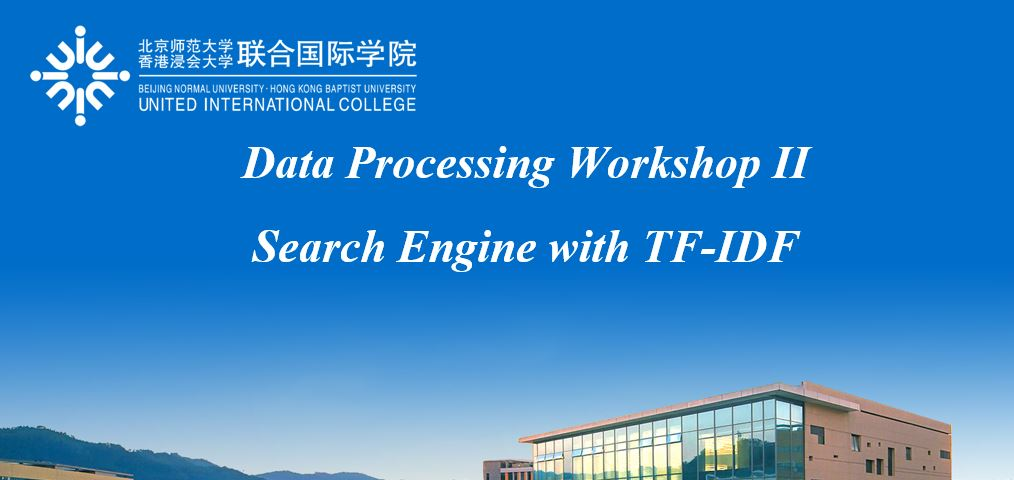

Enter search keyword: i love thomas



search time: 27345.23 ms
[(14240.939320164087, 'PG11729_raw.txt'), (7998.840241128953, 'PG11071_raw.txt'), (7122.182780460178, 'PG100_raw.txt'), (5455.564588367945, 'PG11934_raw.txt'), (4323.540998642061, 'PG10117_raw.txt'), (4308.863519695195, 'PG10829_raw.txt'), (3032.637562264707, 'PG10686_raw.txt'), (2556.834890899761, 'PG10800_raw.txt'), (1420.9227780008378, 'PG10215_raw.txt'), (1335.5516538643312, 'PG10218_raw.txt')]


-------------------- Search Website END --------------------


-------------------- Search Website START --------------------




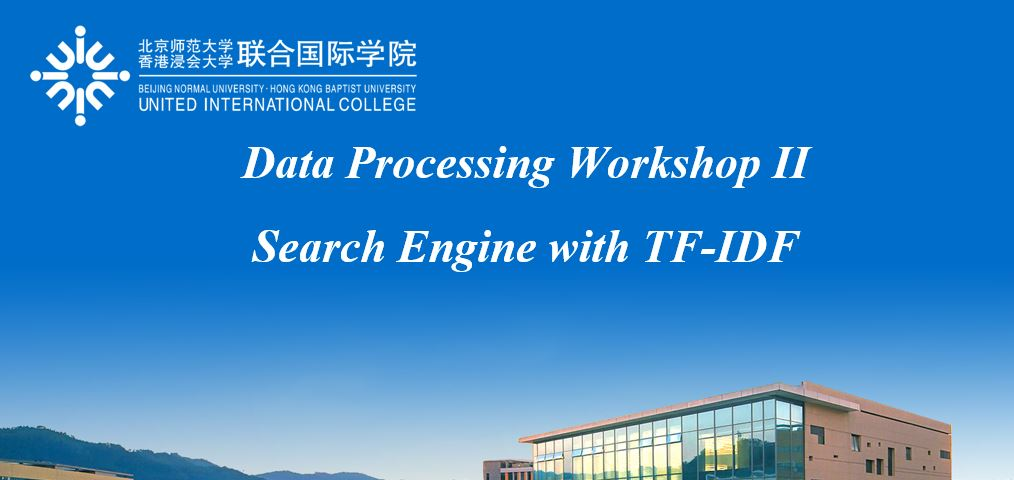

In [9]:
run_query_loop()